# Pytorch Fundamentals

In [1]:
#pip install torch

In [2]:
import torch
import numpy as np
import pandas as pd

In [3]:
print("PyTroch version:",torch.__version__)

PyTroch version: 2.15.0+cu132


In [4]:
print("GPU availability:", torch.cuda.is_available())

GPU availability: False


I will procced with CPU for the basic purpose

1. Tensor -- It is a data structure that stores numeric values. It similar to a Numply array, but PyTorch tensors also support automatic gradient calculation and GPU computation.

EX A - Scalar (0 dimentional tensor)

In [5]:
a = torch.tensor(10)

print(a)
print(a.shape)
print(a.ndim)

tensor(10)
torch.Size([])
0


The scalar contains just one numerical value

Ex. B Vector (1 - dimensional tensor)

In [6]:
b = torch.tensor([10, 20, 30, 40])

print(b)
print(b.shape)
print(b.ndim)

tensor([10, 20, 30, 40])
torch.Size([4])
1


Ex. C Matrix (2 demnsional tensor)

In [7]:
c = torch.tensor([
    [10, 20],
    [30, 40],
    [50, 60]
])

print(c)
print(c.shape)
print(c.ndim)

tensor([[10, 20],
        [30, 40],
        [50, 60]])
torch.Size([3, 2])
2


NumPy Array V/S Torch Tensor

In [8]:
np_array = np.array([1,2,3,4])

torch_tensor = torch.tensor([1, 2, 3, 4])

print(np_array)
print(torch_tensor)

[1 2 3 4]
tensor([1, 2, 3, 4])


In [9]:
# Numpy to torch
tensor_from_numpy = torch.from_numpy(np_array)

# Pytorch to numpy
numpy_from_tensor = torch_tensor.numpy()

print(tensor_from_numpy)
print(numpy_from_tensor)

tensor([1, 2, 3, 4])
[1 2 3 4]


Mathematical operations with tensor



In [10]:
x = torch.tensor([10, 20, 30])

y = torch.tensor([1, 2, 3])

print("Addition:", x + y)
print("Subtraction:", x - y)
print("Multiplication", x * y)
print("Division", x / y)

Addition: tensor([11, 22, 33])
Subtraction: tensor([ 9, 18, 27])
Multiplication tensor([10, 40, 90])
Division tensor([10., 10., 10.])


Matrix Multipication

In [11]:
A = torch.tensor([
    [1, 2],
    [3, 4]
], dtype=torch.float32)

B = torch.tensor([
    [5, 6],
    [7, 8]
], dtype =torch.float32)

result = torch.matmul(A, B)
print(result)


tensor([[19., 22.],
        [43., 50.]])


Automatic Differentiation (Autograd)

In [12]:
x = torch.tensor(5.0, requires_grad=True)

# Define Mathematical Equation
y = x**2 + 3*x + 2

y.backward() # Calcultes gradient using back propogation

print("Value of y:", y.item()) # Value after putting x = 5
print("Gradient:", x.grad.item()) # retrie calculated gradients



Value of y: 42.0
Gradient: 13.0


In [13]:
# Ex.

x = torch.tensor(4.0, requires_grad=True)

y = 3*x**2 + 2*x + 5

# calculating gradient using back propogation
y.backward()

print("Value of y:", y.item())
print("Gradient", x.grad.item())

Value of y: 61.0
Gradient 26.0


### Building Neural Network 

Two input variable
- Age
- Monthy Income

Target Variable
- 0 = Customer does not purchase
- 1 = Customer Purchases

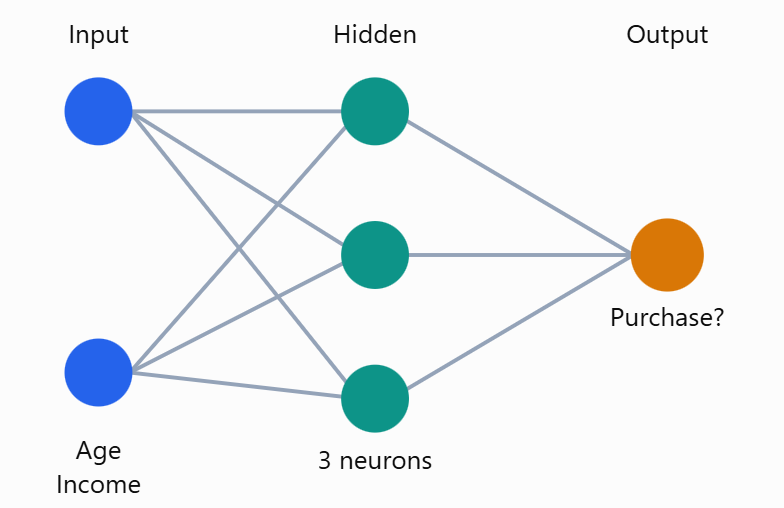

In [14]:
# import torch
import torch.nn as nn
import torch.optim as optim
#import numpy as np

In [15]:
# Create dataset
X = np.array([
    [22, 20],
    [25, 25],
    [35, 60],
    [45, 80],
    [30, 40],
    [40, 70]
], dtype=np.float32)

y = np.array([
    [0],
    [0],
    [1],
    [1],
    [0],
    [1]
], dtype=np.float32)

In [16]:
# conevert numpy array to pytorch tensor

X_tensor = torch.tensor(X)
y_tensor = torch.tensor(y)

print("Shape X", X_tensor.shape)
print("Shape y", y_tensor.shape)

Shape X torch.Size([6, 2])
Shape y torch.Size([6, 1])


In [17]:
# Normalise the input data

mean = X_tensor.mean(dim=0)
std = X_tensor.std(dim=0, unbiased=False)

X_tensor = (X_tensor - mean)/std

In [18]:
class CustomerNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.hidden = nn.Linear(2, 3)
        self.output = nn.Linear(3, 1)

    def forward(self, x):

        x = torch.relu(self.hidden(x))

        x = self.output(x)

        return x

In [19]:
model = CustomerNN()

print(model)

CustomerNN(
  (hidden): Linear(in_features=2, out_features=3, bias=True)
  (output): Linear(in_features=3, out_features=1, bias=True)
)


Binary Cross Entropy with Logits Loss

In [20]:
loss_function = nn.BCEWithLogitsLoss()

Optimizer


In [21]:
optimizer = optim.Adam(
    model.parameters(),
    lr = 0.01
)

In [22]:
epochs = 2000

for epoch in range(epochs):

    # Forward Propogation
    prediction = model(X_tensor)

    # Calculate Loss
    loss = loss_function(prediction, y_tensor)

    # clear previous gradient 
    optimizer.zero_grad()

    # Backpropogation
    loss.backward()

    # Update weights
    optimizer.step()

    if epoch % 200 == 0:
        print(f"Epoch: {epoch}, Loss: {loss.item():.2f}")

Epoch: 0, Loss: 0.61
Epoch: 200, Loss: 0.08


Epoch: 400, Loss: 0.03
Epoch: 600, Loss: 0.02
Epoch: 800, Loss: 0.01
Epoch: 1000, Loss: 0.01
Epoch: 1200, Loss: 0.01
Epoch: 1400, Loss: 0.00
Epoch: 1600, Loss: 0.00
Epoch: 1800, Loss: 0.00


In [26]:
model.eval()

with torch.no_grad():

    logits = model(X_tensor)

    probabilities = torch.sigmoid(logits)

    predicted_classes = (probabilities >= 0.5).float()

print("Predicted probabilities:")
print(probabilities)

print("\nPredicted Classes:")
print(predicted_classes)

print("\nActual Classes:")
print(y_tensor)

Predicted probabilities:
tensor([[0.0049],
        [0.0049],
        [0.9998],
        [1.0000],
        [0.0049],
        [1.0000]])

Predicted Classes:
tensor([[0.],
        [0.],
        [1.],
        [1.],
        [0.],
        [1.]])

Actual Classes:
tensor([[0.],
        [0.],
        [1.],
        [1.],
        [0.],
        [1.]])
